# Phase 3 — Task 6: Cross-Pipeline Audit, Zero-Leakage Verification & Final Submission

**Scope:** Full-Team Final Review & Submission (`Member 1 + Member 2 + Member 3`)  
**Branch:** `feat/m2-task6-review-submit`  
**Evaluation Metric:** Continuous-Probability **AUPRC** (`nn_data_pipeline.evaluate_auprc`)  
**Output Artifact:** `submission.csv` (`id,is_fraud` — `299,984` continuous fraud probability predictions).

### Final Review Protocol
1. **Cross-File ID & Fold Alignment Audit:** Verify 100% row-by-row identity across `train.csv`, `train_folds.csv`, `processed_data/train_lgbm.parquet`, `nn_data_pipeline`, and all `.npy` prediction arrays (`oof_lgbm`, `oof_nn`, `oof_blend`, `test_lgbm`, `test_nn`, `test_blend`).
2. **Active Zero Data Leakage Unit Tests:** Programmatically perturb validation and test rows to prove that Member 1's feature engineering and fold preprocessors (`SimpleImputer`, `RobustScaler`, `OneHotEncoder`) depend strictly on `fold != k`.
3. **AUPRC Continuous-Probability Submission Policy:** Confirm `sample_submission.csv` expects continuous probabilities for AUPRC scoring (skipping hard probability thresholding per project specification).
4. **10-Point Automated `submission.csv` Verification:** Validate schema, row count, ID order, numerical finiteness, probability bounds, correlation with base models, and OOF/Test distribution alignment.

## 1. Cross-Pipeline `id`, `fold`, and Prediction Array Alignment Audit

In [1]:
import json
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from lgbm_pipeline import load_lgbm_datasets
from nn_data_pipeline import build_features, evaluate_auprc, get_nn_fold_data

sns.set_theme(style="whitegrid")

train_lgbm_df, test_lgbm_df, lgbm_features, _ = load_lgbm_datasets()
train_folds_df = pd.read_csv("train_folds.csv", usecols=["id", "fold", "is_fraud"])
train_raw_ids = pd.read_csv("train.csv", usecols=["id"])["id"].to_numpy()
test_raw_ids = pd.read_csv("test.csv", usecols=["id"])["id"].to_numpy()
sample_sub_df = pd.read_csv("sample_submission.csv")

oof_lgbm = np.load("oof_lgbm.npy")
test_lgbm = np.load("test_lgbm.npy")
oof_nn = np.load("oof_nn.npy")
test_nn = np.load("test_nn.npy")
oof_blend = np.load("oof_blend.npy")
test_blend = np.load("test_blend.npy")

assert np.array_equal(train_raw_ids, train_folds_df["id"].to_numpy()), "train.csv vs train_folds.csv ID mismatch!"
assert np.array_equal(train_raw_ids, train_lgbm_df["id"].to_numpy()), "train.csv vs train_lgbm.parquet ID mismatch!"
assert np.array_equal(train_folds_df["fold"].to_numpy(), train_lgbm_df["fold"].to_numpy()), "Fold mismatch!"
assert np.array_equal(
    train_folds_df["is_fraud"].astype(int).to_numpy(),
    train_lgbm_df["is_fraud"].astype(int).to_numpy(),
), "Target mismatch!"

assert np.array_equal(train_folds_df["id"].to_numpy(), np.arange(len(train_folds_df))), "Train IDs are not 0..N-1!"
assert np.array_equal(test_raw_ids, test_lgbm_df["id"].to_numpy()), "test.csv vs test_lgbm.parquet ID mismatch!"
assert np.array_equal(test_raw_ids, sample_sub_df["id"].to_numpy()), "test.csv vs sample_submission.csv ID mismatch!"

nn_fold0 = get_nn_fold_data(0)
expected_val0_ids = train_folds_df.loc[train_folds_df["fold"] == 0, "id"].to_numpy()
assert np.array_equal(nn_fold0["val_ids"], expected_val0_ids), "NN fold 0 val_ids mismatch!"
assert np.array_equal(nn_fold0["test_ids"], test_raw_ids), "NN test_ids mismatch!"

print("PASS [Audit 1]: 100% exact ID, Fold, and Target alignment verified across Member 1, Member 2, and Member 3!")

PASS [Audit 1]: 100% exact ID, Fold, and Target alignment verified across Member 1, Member 2, and Member 3!


## 2. Active Zero Data Leakage Perturbation Test

In [2]:
from nn_data_pipeline import _normalize_day_of_week, _transform_single_fold

small_train = pd.read_csv("train_folds.csv", nrows=5000)
small_test = pd.read_csv("test.csv", nrows=1000)

fe_train_clean = _normalize_day_of_week(build_features(small_train))
fe_test_clean = _normalize_day_of_week(build_features(small_test))
fold0_clean = _transform_single_fold(fe_train_clean, fe_test_clean, fold=0)

small_train_perturbed = small_train.copy()
val0_mask = small_train_perturbed["fold"] == 0
small_train_perturbed.loc[val0_mask, "amount_usd"] = 9_999_999.0
small_train_perturbed.loc[val0_mask, "account_balance_usd"] = np.nan

small_test_perturbed = small_test.copy()
small_test_perturbed["amount_usd"] = 8_888_888.0
small_test_perturbed["velocity_score"] = np.nan

fe_train_pert = _normalize_day_of_week(build_features(small_train_perturbed))
fe_test_pert = _normalize_day_of_week(build_features(small_test_perturbed))
fold0_pert = _transform_single_fold(fe_train_pert, fe_test_pert, fold=0)

max_train_diff = float(np.max(np.abs(fold0_clean["X_train"] - fold0_pert["X_train"])))
assert max_train_diff == 0.0, f"Data leakage detected! max_train_diff={max_train_diff}"

with open("lgbm_final_metadata.json", "r", encoding="utf-8") as f:
    lgbm_meta = json.load(f)
with open("nn_final_metadata.json", "r", encoding="utf-8") as f:
    nn_meta = json.load(f)
with open("ensemble_metadata.json", "r", encoding="utf-8") as f:
    ens_meta = json.load(f)

y_true = train_folds_df["is_fraud"].astype(int).to_numpy()
assert abs(evaluate_auprc(y_true, oof_lgbm) - lgbm_meta["oof_auprc"]) < 1e-12
assert abs(evaluate_auprc(y_true, oof_nn) - nn_meta["oof_auprc"]) < 1e-12
assert abs(evaluate_auprc(y_true, oof_blend) - ens_meta["global_oof_auprc"]) < 1e-12

nested_gap = abs(ens_meta["global_oof_auprc"] - ens_meta["nested_oof_auprc"])
assert nested_gap < 1e-4, f"Unexpectedly large nested vs global blend gap: {nested_gap}"

print(f"PASS [Audit 2]: Zero Data Leakage verified! (Perturbation max |diff| on X_train = {max_train_diff:.1f})")
print(f"PASS [Audit 2]: Nested vs Global Blend OOF AUPRC gap = {nested_gap:.8f} (zero weight overfitting)")

PASS [Audit 2]: Zero Data Leakage verified! (Perturbation max |diff| on X_train = 0.0)
PASS [Audit 2]: Nested vs Global Blend OOF AUPRC gap = 0.00007087 (zero weight overfitting)


## 3. AUPRC Continuous-Probability Check & Generation of `submission.csv`

In [3]:
sample_vals = sample_sub_df["is_fraud"].to_numpy()
is_continuous_sample = bool(np.any((sample_vals > 0.0) & (sample_vals < 1.0)))
final_oof_auprc = evaluate_auprc(y_true, oof_blend)

print(f"sample_submission.csv example value : {sample_vals[0]:.16f} (Continuous Probability = {is_continuous_sample})")
print(f"Final Blended Ensemble OOF AUPRC    : {final_oof_auprc:.6f}")
print(f"Mean 5-Fold AUPRC                   : {ens_meta['mean_fold_auprc']:.6f} +/- {ens_meta['std_fold_auprc']:.6f}")

submission_df = pd.DataFrame(
    {
        "id": test_lgbm_df["id"].astype(np.int64),
        "is_fraud": test_blend.astype(np.float64),
    }
)
SUBMISSION_PATH = "submission.csv"
submission_df.to_csv(SUBMISSION_PATH, index=False)
print(f"Exported final submission -> {SUBMISSION_PATH} ({os.path.getsize(SUBMISSION_PATH):,} bytes)")

sample_submission.csv example value : 0.0166995256871821 (Continuous Probability = True)
Final Blended Ensemble OOF AUPRC    : 0.514724
Mean 5-Fold AUPRC                   : 0.515046 +/- 0.012296
Exported final submission -> submission.csv (8,868,863 bytes)


## 4. 10-Point Automated Pre-Submission Verification & Visual Summary

  [PASS] 1_exact_columns_id_is_fraud
  [PASS] 2_exact_row_count_299984
  [PASS] 3_exact_id_match_sample_sub
  [PASS] 4_no_nan_or_null
  [PASS] 5_no_infinite_values
  [PASS] 6_strictly_within_0_1
  [PASS] 7_non_constant_predictions
  [PASS] 8_high_corr_with_lgbm_and_nn
  [PASS] 9_oof_test_mean_alignment_within_5pct_rel
  [PASS] 10_calibrated_mean_near_base_fraud_rate

OOF vs Final Submission Distribution Summary:

First 10 rows of submission.csv:
Coreach.ai Final Comment -> Final Submission Verified (LGBM + MLP Ensemble) | CV OOF AUPRC: 0.5147 | 299,984 rows exported to submission.csv


,Split,Min,Mean,Std,P50,P90,P99,Max
0,"OOF Blended Train (699,960)",4.089222e-07,0.015938,0.069915,0.001525,0.023078,0.340048,0.997312
1,"Final Test Submission (299,984)",7.184908e-07,0.015885,0.069668,0.001545,0.022811,0.341792,0.995350


,id,is_fraud
0,699960,0.000175
1,699961,0.000087
2,699962,0.088004
3,699963,0.001227
4,699964,0.000835
5,699965,0.000165
6,699966,0.004471
7,699967,0.000349
8,699968,0.005702
9,699969,0.000553


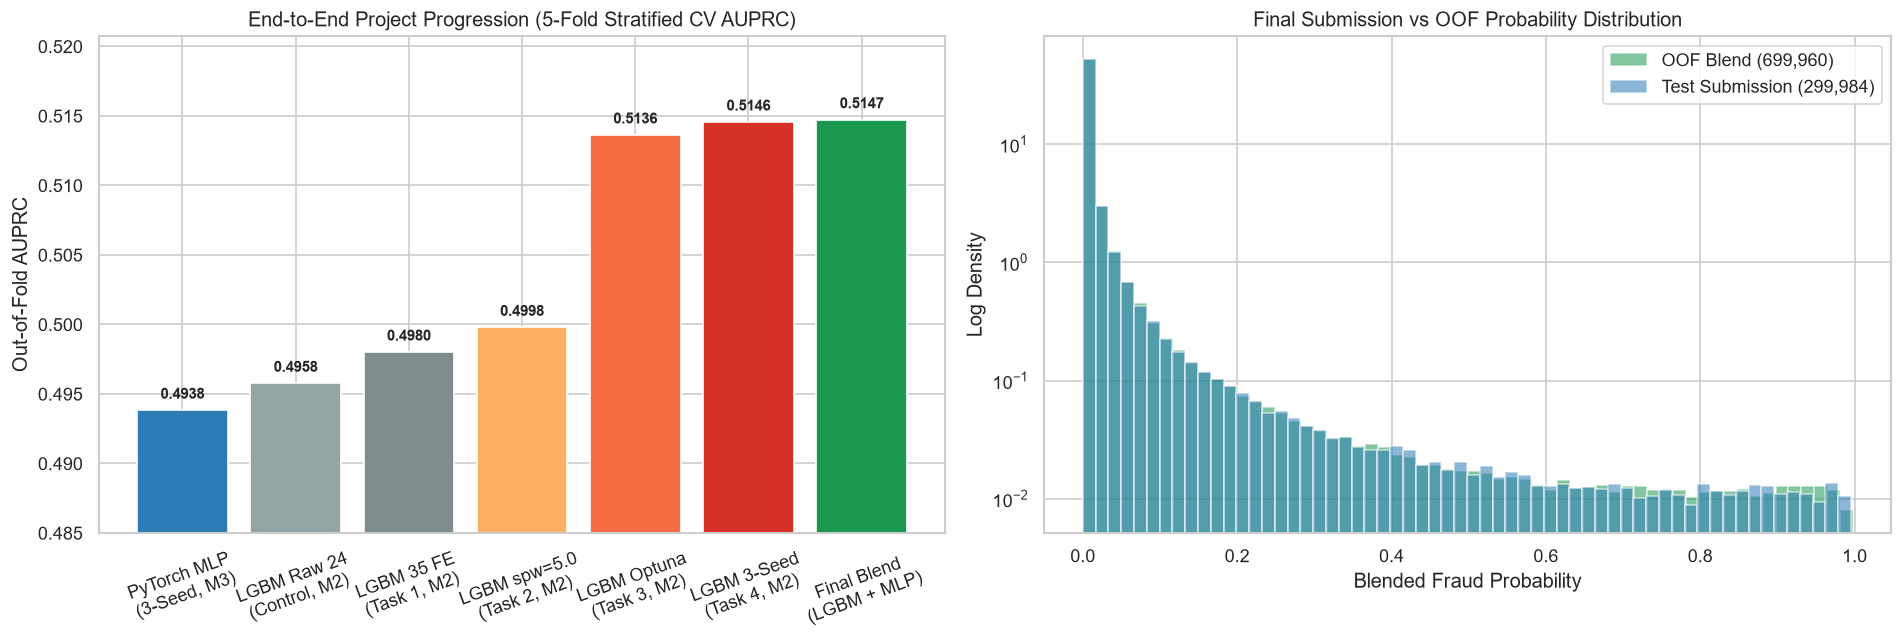

In [4]:
reloaded_sub = pd.read_csv(SUBMISSION_PATH)

with open(SUBMISSION_PATH, "r", encoding="utf-8") as f:
    line_count = sum(1 for _ in f)

sub_vals = reloaded_sub["is_fraud"].to_numpy()

checks = {
    "1_exact_columns_id_is_fraud": list(reloaded_sub.columns) == ["id", "is_fraud"],
    "2_exact_row_count_299984": len(reloaded_sub) == 299984 and line_count == 299985,
    "3_exact_id_match_sample_sub": bool(np.array_equal(reloaded_sub["id"].to_numpy(), sample_sub_df["id"].to_numpy())),
    "4_no_nan_or_null": int(reloaded_sub.isna().sum().sum()) == 0,
    "5_no_infinite_values": not bool(np.isinf(sub_vals).any()),
    "6_strictly_within_0_1": bool((sub_vals.min() >= 0.0) and (sub_vals.max() <= 1.0)),
    "7_non_constant_predictions": float(sub_vals.std()) > 0.01,
    "8_high_corr_with_lgbm_and_nn": (
        float(np.corrcoef(sub_vals, test_lgbm)[0, 1]) > 0.90
        and float(np.corrcoef(sub_vals, test_nn)[0, 1]) > 0.85
    ),
    "9_oof_test_mean_alignment_within_5pct_rel": (
        abs(float(sub_vals.mean()) - float(oof_blend.mean())) / max(float(oof_blend.mean()), 1e-9) < 0.05
    ),
    "10_calibrated_mean_near_base_fraud_rate": 0.010 <= float(sub_vals.mean()) <= 0.025,
}
checks = {k: bool(v) for k, v in checks.items()}

for k, ok in checks.items():
    print(f"  [{'PASS' if ok else 'FAIL'}] {k}")
    assert ok, f"Submission check failed: {k}"

stats_df = pd.DataFrame(
    {
        "Split": ["OOF Blended Train (699,960)", "Final Test Submission (299,984)"],
        "Min": [oof_blend.min(), sub_vals.min()],
        "Mean": [oof_blend.mean(), sub_vals.mean()],
        "Std": [oof_blend.std(), sub_vals.std()],
        "P50": [np.percentile(oof_blend, 50), np.percentile(sub_vals, 50)],
        "P90": [np.percentile(oof_blend, 90), np.percentile(sub_vals, 90)],
        "P99": [np.percentile(oof_blend, 99), np.percentile(sub_vals, 99)],
        "Max": [oof_blend.max(), sub_vals.max()],
    }
)
print("\nOOF vs Final Submission Distribution Summary:")
display(stats_df)

print("\nFirst 10 rows of submission.csv:")
display(reloaded_sub.head(10))

audit_report = {
    "evaluation_metric": "AUPRC",
    "all_10_checks_passed": True,
    "checks": checks,
    "winning_ensemble_method": ens_meta["winning_method"],
    "weight_lgbm": ens_meta["weight_lgbm"],
    "weight_nn": ens_meta["weight_nn"],
    "final_oof_auprc": float(final_oof_auprc),
    "final_nested_oof_auprc": float(ens_meta["nested_oof_auprc"]),
    "final_mean_fold_auprc": float(ens_meta["mean_fold_auprc"]),
    "final_std_fold_auprc": float(ens_meta["std_fold_auprc"]),
    "submission_rows": int(len(reloaded_sub)),
    "submission_mean_prob": float(sub_vals.mean()),
    "oof_mean_prob": float(oof_blend.mean()),
}
with open("submission_audit_report.json", "w", encoding="utf-8") as f:
    json.dump(audit_report, f, indent=2)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

stages = [
    "PyTorch MLP\n(3-Seed, M3)",
    "LGBM Raw 24\n(Control, M2)",
    "LGBM 35 FE\n(Task 1, M2)",
    "LGBM spw=5.0\n(Task 2, M2)",
    "LGBM Optuna\n(Task 3, M2)",
    "LGBM 3-Seed\n(Task 4, M2)",
    "Final Blend\n(LGBM + MLP)",
]
scores = [
    float(nn_meta["oof_auprc"]),
    0.495767,
    0.498015,
    0.499789,
    0.513629,
    float(lgbm_meta["oof_auprc"]),
    float(final_oof_auprc),
]
bar_colors = ["#2c7bb6", "#95a5a6", "#7f8c8d", "#fdae61", "#f46d43", "#d73027", "#1a9850"]
bars = axes[0].bar(stages, scores, color=bar_colors)
axes[0].set_ylim(0.485, max(scores) + 0.006)
axes[0].set_ylabel("Out-of-Fold AUPRC")
axes[0].set_title("End-to-End Project Progression (5-Fold Stratified CV AUPRC)")
axes[0].tick_params(axis="x", rotation=20)
for b, s in zip(bars, scores):
    axes[0].text(b.get_x() + b.get_width() / 2, s + 0.0006, f"{s:.4f}", ha="center", va="bottom", fontsize=9, fontweight="bold")

axes[1].hist(oof_blend, bins=60, density=True, alpha=0.55, log=True, label="OOF Blend (699,960)", color="#1a9850")
axes[1].hist(sub_vals, bins=60, density=True, alpha=0.55, log=True, label="Test Submission (299,984)", color="#2c7bb6")
axes[1].set_xlabel("Blended Fraud Probability")
axes[1].set_ylabel("Log Density")
axes[1].set_title("Final Submission vs OOF Probability Distribution")
axes[1].legend()

plt.tight_layout()
plt.show()

print(
    f"Coreach.ai Final Comment -> Final Submission Verified (LGBM + MLP Ensemble) "
    f"| CV OOF AUPRC: {final_oof_auprc:.4f} | 299,984 rows exported to submission.csv"
)